# Roi Analysis

Owner: 

Input: 

Output: 

ROI Analysis
Objective
The objective of this analysis is to evaluate the effectiveness of marketing investments using Return on Investment (ROI) and Return on Advertising Spend (ROAS). This analysis identifies the effectiveness of marketing expenditures and provides insights for future marketing decisions.

In [8]:
import sys
sys.path.append('..')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('default')
sns.set_theme(style="whitegrid")

In [9]:
df = pd.read_csv(
    "../data/processed/feature_engineered_marketing_mix_data.csv"
)

print("Dataset Shape:", df.shape)

df.head()

Dataset Shape: (36, 44)


,month,country,brand_category,region_scope,tv_spend_lkr,facebook_instagram_spend_lkr,google_search_spend_lkr,youtube_spend_lkr,radio_spend_lkr,outdoor_spend_lkr,...,revenue_per_unit,revenue_per_conversion,roas,cost_per_conversion,lag_1_total_spend,lag_2_total_spend,rolling_3_month_spend,marketing_pressure,competitive_advantage,promotion_impact
0,2023-01-01,Sri Lanka,FMCG - Packaged Foods,National,4274762,3890003,2467793,1836858,1700676,1813444,...,558.637776,57.943069,4.386643,13.208977,0.0,0.0,0.000000e+00,12469416,50.4,7.8516
1,2023-02-01,Sri Lanka,FMCG - Packaged Foods,National,4023574,5062635,2962576,2254198,1922384,2941194,...,633.780115,110.710778,3.839737,28.832909,15983536.0,0.0,0.000000e+00,14302983,49.0,9.0912
2,2023-03-01,Sri Lanka,FMCG - Packaged Foods,National,5359091,3746337,4080535,2363737,1720670,2063917,...,562.908050,223.483184,4.399608,50.796156,19166561.0,15983536.0,1.816146e+07,15549700,54.1,6.8300
3,2023-04-01,Sri Lanka,FMCG - Packaged Foods,National,5102550,3690115,3390558,2595121,1217450,3091430,...,533.883913,81.452943,5.242138,15.538116,19334287.0,19166561.0,1.919602e+07,14778344,68.8,25.6088
4,2023-05-01,Sri Lanka,FMCG - Packaged Foods,National,4972723,5333813,3240078,2343364,1568285,3525300,...,461.062423,137.662905,3.693476,37.271909,19087224.0,19334287.0,1.980169e+07,15889978,47.0,2.1450


MMM-Based Sales Prediction

In [2]:
import sys
sys.path.append('..')

import src.predict as predict

dir(predict)

['Any',
 'Dict',
 'List',
 'MMMPredictor',
 'Optional',
 'Path',
 'Tuple',
 'Union',
 '__builtins__',
 '__cached__',
 '__doc__',
 '__file__',
 '__loader__',
 '__name__',
 '__package__',
 '__spec__',
 'apply_adstock_with_carryover',
 'geometric_adstock',
 'hill_saturation',
 'joblib',
 'json',
 'np',
 'pd',
 'predict_sales']

In [5]:
from src.predict import MMMPredictor

predictor = MMMPredictor(
    model_path="../outputs/models/ridge_mmm_baseline.joblib",
    config_path="../outputs/models/model_config.json",
    transform_params_path="../outputs/models/transformation_params.json"
)

print(type(predictor))

c:\ProgramData\anaconda3\Lib\site-packages\sklearn\base.py:376: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.9.0 when using version 1.5.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


<class 'src.predict.MMMPredictor'>


c:\ProgramData\anaconda3\Lib\site-packages\sklearn\base.py:376: InconsistentVersionWarning: Trying to unpickle estimator Ridge from version 1.9.0 when using version 1.5.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\base.py:376: InconsistentVersionWarning: Trying to unpickle estimator Pipeline from version 1.9.0 when using version 1.5.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


In [10]:
baseline_sales = predictor.predict(df)

print(baseline_sales[:5])

[72717884.64470913 77890560.59763534 82233154.84897667 96997152.52500947
 84175335.38098845]


In [11]:
df["baseline_sales"] = baseline_sales

baseline_total = baseline_sales.sum()

print(f"Total Predicted Sales: {baseline_total:,.2f}")

Total Predicted Sales: 3,062,308,458.49


Channel Contribution Analysis

In [12]:
channels = [
    'tv_spend_lkr',
    'facebook_instagram_spend_lkr',
    'google_search_spend_lkr',
    'youtube_spend_lkr',
    'radio_spend_lkr',
    'outdoor_spend_lkr'
]

results = []

for channel in channels:

    scenario = df.copy()

    scenario[channel] = 0

    sales_without_channel = (
        predictor.predict(scenario)
        .sum()
    )

    contribution = (
        baseline_total
        - sales_without_channel
    )

    spend = df[channel].sum()

    roi = contribution / spend

    results.append([
        channel,
        spend,
        contribution,
        roi
    ])

roi_df = pd.DataFrame(
    results,
    columns=[
        "Channel",
        "Spend",
        "Contribution",
        "ROI"
    ]
)

roi_df

,Channel,Spend,Contribution,ROI
0,tv_spend_lkr,156964242,4.076953e+08,2.597377
1,facebook_instagram_spend_lkr,158343617,1.986069e+08,1.254278
2,google_search_spend_lkr,119353135,5.228800e+08,4.380949
3,youtube_spend_lkr,79913729,3.872768e+08,4.846186
4,radio_spend_lkr,60107999,-4.390734e+08,-7.304742
5,outdoor_spend_lkr,94057802,2.237474e+08,2.378829


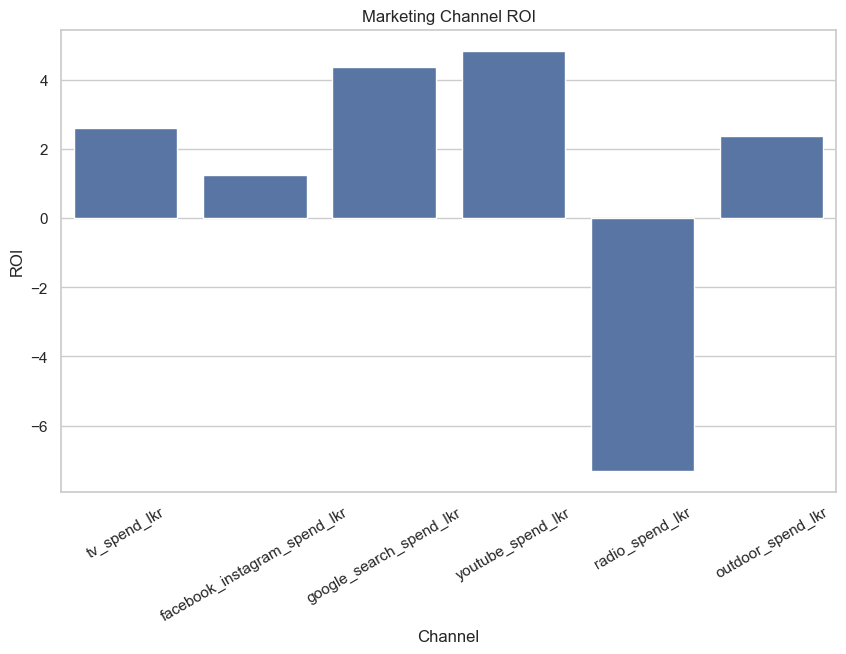

In [13]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=roi_df,
    x="Channel",
    y="ROI"
)

plt.title("Marketing Channel ROI")
plt.xticks(rotation=30)

plt.show()

In [14]:
best_channel = roi_df.loc[roi_df["ROI"].idxmax()]
worst_channel = roi_df.loc[roi_df["ROI"].idxmin()]

print("Best Performing Channel")
print(best_channel)

print("\nWorst Performing Channel")
print(worst_channel)

Best Performing Channel
Channel         youtube_spend_lkr
Spend                    79913729
Contribution     387276823.087812
ROI                      4.846186
Name: 3, dtype: object

Worst Performing Channel
Channel          radio_spend_lkr
Spend                   60107999
Contribution   -439073425.152092
ROI                    -7.304742
Name: 4, dtype: object


Channel Spending Analysis
This section examines how advertising budgets were distributed across different marketing channels.

In [16]:
channel_cols = [
    'tv_spend_lkr',
    'facebook_instagram_spend_lkr',
    'google_search_spend_lkr',
    'youtube_spend_lkr',
    'radio_spend_lkr',
    'outdoor_spend_lkr'
]

channel_spend = df[channel_cols].sum()

channel_spend.sort_values(
    ascending=False
)

facebook_instagram_spend_lkr    158343617
tv_spend_lkr                    156964242
google_search_spend_lkr         119353135
outdoor_spend_lkr                94057802
youtube_spend_lkr                79913729
radio_spend_lkr                  60107999
dtype: int64

Key Findings
The Marketing Mix Model predicted total sales of approximately LKR 3.06 billion.
YouTube generated the highest ROI (4.85), making it the most efficient marketing channel.

Google Search achieved the second-highest ROI (4.38), demonstrating strong sales contribution relative to advertising spend.

TV advertising generated a positive ROI (2.60), supporting its continued role in the marketing mix.

Outdoor advertising delivered moderate positive returns (2.38).

Facebook/Instagram achieved a positive ROI (1.25), although lower than other major channels.

Radio advertising produced a negative ROI (-7.30), indicating weak contribution to sales performance.

Recommendations
Increase investment in YouTube advertising due to its highest ROI.
Allocate additional budget to Google Search campaigns because of strong return potential.

Continue investing in TV advertising while improving campaign efficiency.

Review Facebook and Instagram audience targeting strategies to improve performance.

Reassess radio advertising expenditure and consider reducing allocation.

Prioritize channels with stronger incremental sales contribution in future campaigns.

Conclusion
ROI analysis was conducted using Marketing Mix Model predictions and incremental channel contribution analysis. The results showed that YouTube and Google Search generated the strongest returns, while Radio demonstrated negative performance. These findings provide a data-driven basis for future budget allocation and optimization decisions.